In [1]:
from pathlib import Path
import rasterio

ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
POP = ROOT / "data" / "raw" / "population" / "cmr_pop_2025_CN_100m_R2025A_v1.tif"

with rasterio.open(POP) as src:
    print("CRS:", src.crs)
    print("Size (cols x rows):", src.width, "x", src.height)
    print("Cell size:", src.res)
    print("NoData value:", src.nodata)
    print("Bounds:", src.bounds)

CRS: EPSG:4326
Size (cols x rows): 9236 x 13712
Cell size: (0.00083333333, 0.00083333333)
NoData value: -99999.0
Bounds: BoundingBox(left=8.497499246009998, bottom=1.656666996039986, right=16.194165881889997, top=13.083333616999987)


In [2]:
import numpy as np

total = 0.0
with rasterio.open(POP) as src:
    for _, window in src.block_windows(1):
        block = src.read(1, window=window, masked=True)
        total += float(block.sum()) if block.count() else 0.0

print(f"Total population in raster: {total:,.0f}")

Total population in raster: 29,499,946


          dept_name  pop_department
40          Mfoundi    3.329744e+06
57            Wouri    3.229951e+06
1            Bénoué    1.768086e+06
30     Mayo-Tsanaga    1.310883e+06
5           Diamaré    1.135864e+06
25       Mayo-Danay    9.012076e+05
27       Mayo-Louti    8.695774e+05
21  Logone-et-Chari    8.367082e+05
9              Fako    8.189692e+05
28         Mayo-Rey    7.729379e+05


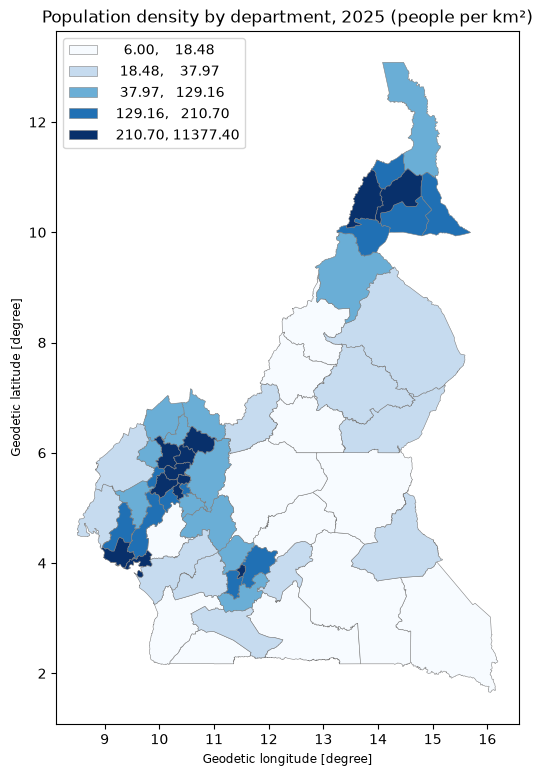

In [12]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

INTERIM = ROOT / "data" / "interim"
dep = gpd.read_file(INTERIM / "departments.geojson")
pop = pd.read_parquet(INTERIM / "population_departments.parquet")
dep = dep.merge(pop[["dept_code", "pop_department"]], on="dept_code")

# Density per km², computed in a metric projection
dep["area_km2"] = dep.to_crs(3857).area / 1e6
dep["density"] = dep["pop_department"] / dep["area_km2"]


fig, ax = plt.subplots(figsize=(8, 9))


dep.plot(column="density", scheme="quantiles", k=5, cmap="Blues",
         edgecolor="grey", linewidth=0.4, legend=True, legend_kwds={"loc": "upper left"}, ax=ax)
ax.set_title("Population density by department, 2025 (people per km²)")


fig.savefig(ROOT / "reports" / "population_density.png", dpi=150, bbox_inches="tight")

print(dep.sort_values("pop_department", ascending=False)[["dept_name", "pop_department"]].head(10))